# Detección de ojos y narices con YOLOv8 — *directo desde la descarga*

### Detección de objetos con YOLOv8 — **ojos y narices**
Visión por Computador · Pontificia Universidad Católica de Chile · adaptado por **Diego**
sobre el material de Domingo Mery.

Diseñamos desde cero un detector de objetos de **dos clases** — `0: ojo`, `1: nariz` —
a partir del dataset *Face-Recognition-1-2* (Roboflow), que ya viene anotado en formato YOLOv8.

> Antes de ejecutar: `Entorno de ejecución → Cambiar tipo de entorno → GPU`.

---
**Este cuaderno** omite por completo el CSV: como el dataset ya viene en formato YOLO con sus
divisiones `train/valid/test`, solo **filtramos las etiquetas** para dejar ojos y narices,
rearmamos la carpeta `data/` y entrenamos.

## (1) Descarga del dataset

In [1]:
!wget -q -O dataset.zip \
https://www.dropbox.com/scl/fi/mkky2tdob9wxmo349w3rk/dataset_yolo.zip?rlkey=886kbkhw1g7g092ikl19l4gk3&st=9nlw1v7o&dl=0
!unzip dataset.zip

Se han truncado las últimas 5000 líneas del flujo de salida.
  inflating: dataset_yolo/train/labels/img_1449.txt  
  inflating: dataset_yolo/train/labels/img_2325.txt  
  inflating: dataset_yolo/train/labels/img_0584.txt  
  inflating: dataset_yolo/train/labels/img_0790.txt  
  inflating: dataset_yolo/train/labels/img_0335.txt  
  inflating: dataset_yolo/train/labels/img_1772.txt  
  inflating: dataset_yolo/train/labels/img_0372.txt  
  inflating: dataset_yolo/train/labels/img_0013.txt  
  inflating: dataset_yolo/train/labels/img_0279.txt  
  inflating: dataset_yolo/train/labels/img_2056.txt  
  inflating: dataset_yolo/train/labels/img_2302.txt  
  inflating: dataset_yolo/train/labels/img_0297.txt  
  inflating: dataset_yolo/train/labels/img_0556.txt  
  inflating: dataset_yolo/train/labels/img_1095.txt  
  inflating: dataset_yolo/train/labels/img_2159.txt  
  inflating: dataset_yolo/train/labels/img_2654.txt  
  inflating: dataset_yolo/train/labels/img_1583.txt  
  inflating: dataset_

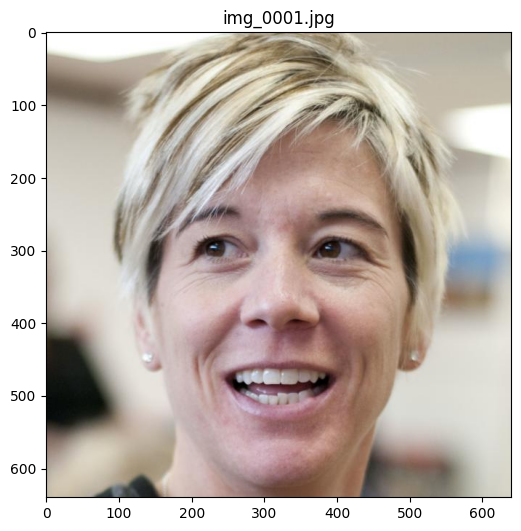

In [3]:
# Despliegue de una imagen de ejemplo
import os, glob, cv2
import numpy as np
import matplotlib.pyplot as plt

ejemplos = sorted(glob.glob('dataset_yolo/test/images/*.jpg'))
X = cv2.imread(ejemplos[0])
plt.figure(figsize=(6, 8))
plt.imshow(cv2.cvtColor(X, cv2.COLOR_BGR2RGB))
plt.title(os.path.basename(ejemplos[0]))
plt.show()

In [6]:
import fnmatch
import yaml

with open('data.yaml') as f:
    cfg = yaml.safe_load(f)

def dirfiles(img_path, img_ext):
    return fnmatch.filter(sorted(os.listdir(img_path)), img_ext)

# YOLOv8

Con la base de datos lista y las anotaciones en el formato requerido, instalamos la librería
[YOLO](https://docs.ultralytics.com/) de Ultralytics y entrenamos.

In [8]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 55.8 MB/s eta 0:00:00


In [9]:
!yolo version

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
8.4.83


In [10]:
from ultralytics import YOLO

## Definiciones

In [13]:
YOLO_MODEL     = 'yolov8s'           # puede ser yolov8n, yolov8m, yolov8l, yolov8x
EPOCHS         = 100
TRAIN_WEIGHTS  = YOLO_MODEL + '.pt'  # pesos preentrenados
BATCH          = 8
IMG_SIZE       = 256
YAMLFILE       = 'data.yaml'    # configuración del dataset

## Entrenamiento

En algunos casos el entrenamiento se interrumpe al principio por <font color='red'>un problema
de memoria caché</font> de Colab con YOLOv8 (`Attempt to free invalid pointer ...`). Si pasa,
reinicia el entorno y vuelve a ejecutar.

In [22]:
model = YOLO(TRAIN_WEIGHTS)

# Entrenamiento
model.train(
    data=YAMLFILE,
    epochs=EPOCHS,
    batch=BATCH,
    imgsz=IMG_SIZE,
    cache=True,
    save=True
)

Ultralytics 8.4.83 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=True, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=256, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-8, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0

Exception in thread Thread-14 (_pin_memory_loop):
Traceback (most recent call last):
  File "/usr/lib/python3.12/threading.py", line 1075, in _bootstrap_inner
    self.run()
  File "/usr/lib/python3.12/threading.py", line 1012, in run
    self._target(*self._args, **self._kwargs)
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/_utils/pin_memory.py", line 52, in _pin_memory_loop
    do_one_step()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/_utils/pin_memory.py", line 28, in do_one_step
    r = in_queue.get(timeout=MP_STATUS_CHECK_INTERVAL)
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/queues.py", line 122, in get
    return _ForkingPickler.loads(res)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/torch/multiprocessing/reductions.py", line 540, in rebuild_storage_fd
    fd = df.detach()
         ^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/resource_

     57/100     0.621G     0.8111     0.4084     0.8524         19        256: 44% ━━━━━─────── 151/337 8.8it/s 11.8s<21.1s


KeyboardInterrupt: 

## Detección en el testing

In [26]:
TEST_WEIGHTS = '/content/runs/detect/train/weights/best.pt'
PATH_TEST    = '/content/dataset_yolo/test/images'

trained_model = YOLO(TEST_WEIGHTS)

# Predicción sobre el conjunto de test
results = trained_model.predict(
    source=PATH_TEST,
    imgsz=256,
    conf=0.4,
    save=True
)


image 1/51 /content/dataset_yolo/test/images/img_0001.jpg: 256x256 2 eyes, 1 nose, 19.4ms
image 2/51 /content/dataset_yolo/test/images/img_0002.jpg: 256x256 3 eyes, 1 nose, 7.1ms
image 3/51 /content/dataset_yolo/test/images/img_0003.jpg: 256x256 2 eyes, 1 nose, 6.8ms
image 4/51 /content/dataset_yolo/test/images/img_0004.jpg: 256x256 2 eyes, 1 nose, 6.8ms
image 5/51 /content/dataset_yolo/test/images/img_0005.jpg: 256x256 2 eyes, 1 nose, 8.5ms
image 6/51 /content/dataset_yolo/test/images/img_0006.jpg: 256x256 2 eyes, 1 nose, 6.9ms
image 7/51 /content/dataset_yolo/test/images/img_0007.jpg: 256x256 2 eyes, 1 nose, 6.8ms
image 8/51 /content/dataset_yolo/test/images/img_0008.jpg: 256x256 2 eyes, 1 nose, 6.7ms
image 9/51 /content/dataset_yolo/test/images/img_0009.jpg: 256x256 2 eyes, 1 nose, 6.9ms
image 10/51 /content/dataset_yolo/test/images/img_0010.jpg: 256x256 2 eyes, 1 nose, 6.8ms
image 11/51 /content/dataset_yolo/test/images/img_0011.jpg: 256x256 2 eyes, 1 nose, 6.8ms
image 12/51 /cont

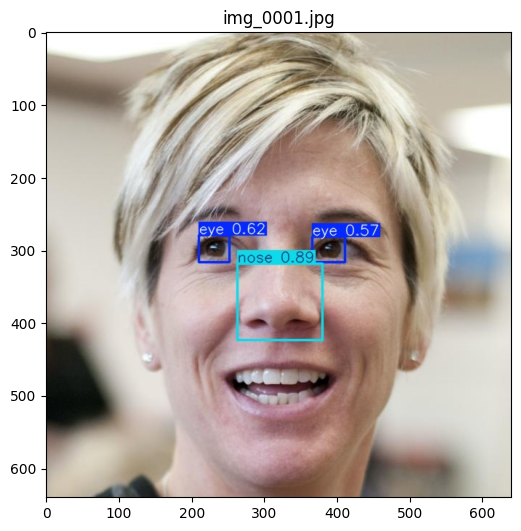

In [27]:
# Mostramos la primera imagen predicha (tomamos el nombre dinámicamente)
pred = sorted(glob.glob('runs/detect/predict/*.jpg'))
X = cv2.imread(pred[0])
plt.figure(figsize=(6, 8))
plt.imshow(cv2.cvtColor(X, cv2.COLOR_BGR2RGB))
plt.title(os.path.basename(pred[0]))
plt.show()

## Estadísticas en testing

In [28]:
metrics = model.val(
    data=YAMLFILE,
    imgsz=IMG_SIZE,
    iou=0.25,
    half=True,
    split="test"
)

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.83 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 11,126,358 parameters, 13,254 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2090.4±560.6 MB/s, size: 44.1 KB)
val: Scanning /content/dataset_yolo/test/labels... 51 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 51/51 811.2it/s 0.1s
val: New cache created: /content/dataset_yolo/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 5.0it/s 0.8s
                   all         51        133      0.858      0.984      0.904      0.651
                   eye         39         80      0.745      0.988      0.824      0.468
                  nose         51         53      0.972      0.981      0.985      0.833
Speed: 0.4ms preprocess, 2.7ms inference, 0.0ms loss, 2.2ms postprocess 

## Despliegue de resultados

In [30]:
def plot_boundingbox(iname, img_path, label_path):
    img_name = img_path + '/' + iname
    print('image:', img_name)
    X = cv2.imread(img_name)
    N = X.shape[0]
    M = X.shape[1]
    plt.figure(figsize=(12, 12))
    plt.imshow(cv2.cvtColor(X, cv2.COLOR_BGR2RGB))
    plt.title(iname)
    lname = label_path + iname[:-4] + '.txt'
    print(' bbox:', lname)
    if os.path.isfile(lname):
        arr = np.loadtxt(lname)
        n = 1 if len(arr.shape) == 1 else arr.shape[0]
        for k in range(n):
            z = arr if n == 1 else arr[k, :]
            cl = int(z[0])
            x = z[1] * M; y = z[2] * N
            w2 = z[3] * M / 2; h2 = z[4] * N / 2
            x1, x2 = x - w2, x + w2
            y1, y2 = y - h2, y + h2
            plt.plot([x1, x1, x2, x2, x1], [y1, y2, y2, y1, y1], 'g')
            plt.text(x1, y1, str(cl), bbox=dict(facecolor='red', alpha=0.5))
    plt.show()

In [32]:
tpath = './dataset_yolo/test/images/'
lpath = './dataset_yolo/test/labels/'
img_names = dirfiles(tpath, '*.jpg')
i = 0

image: runs/detect/predict//img_0003.jpg
 bbox: ./dataset_yolo/test/labels/img_0003.txt


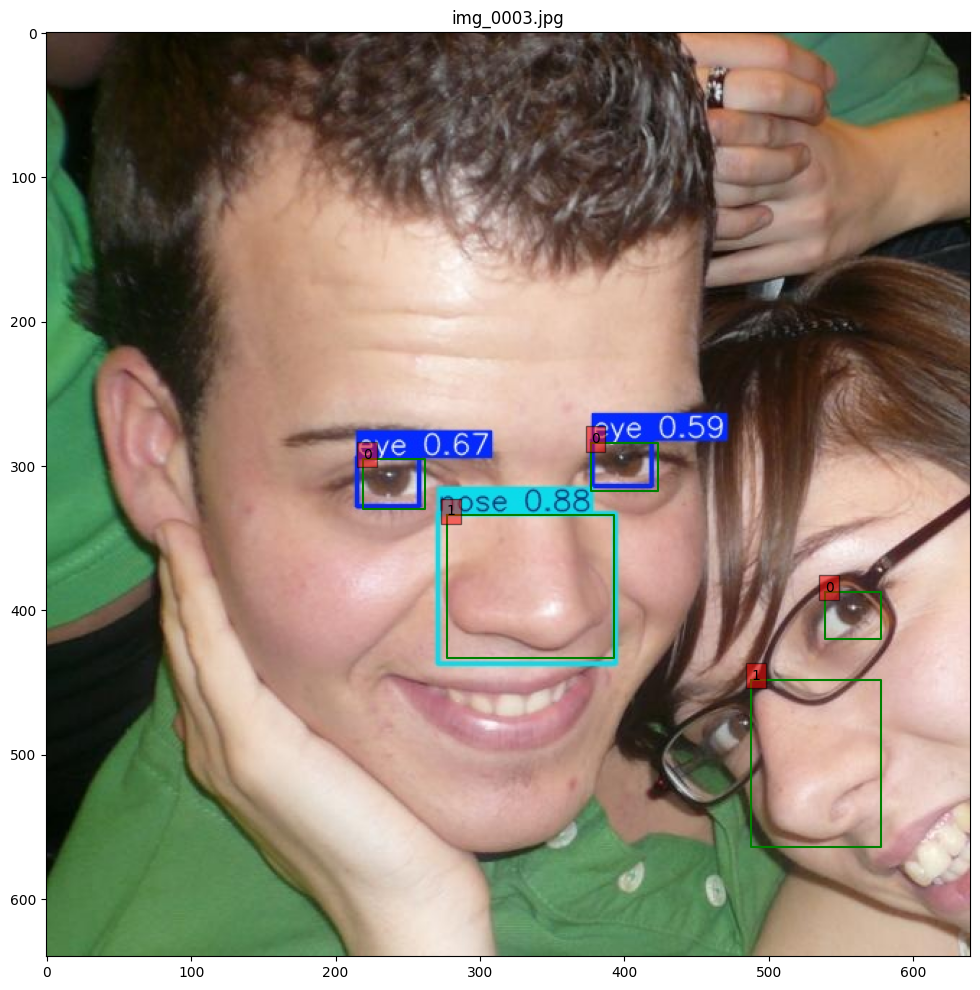

In [33]:
i = i + 2
iname = img_names[i]
img_path = 'runs/detect/predict/'   # ground truth en label_path
label_path = lpath
plot_boundingbox(iname, img_path, label_path)

---
*Cuaderno adaptado para el módulo de Visión por Computador del diplomado de inteligencia artificial aplicada a la industria tecnológica · Universidad de Santiago de Chile.*
---
<a href="https://example.com">06_YOLOv8_directo_ojos_narices.ipynb</a> © 2026 by <a href="https://example.com">Diego Fischer</a> is licensed under <a href="https://creativecommons.org/licenses/by/4.0/">CC BY 4.0</a><img src="https://mirrors.creativecommons.org/presskit/icons/cc.svg" alt="" style="max-width: 1em;max-height:1em;margin-left: .2em;"><img src="https://mirrors.creativecommons.org/presskit/icons/by.svg" alt="" style="max-width: 1em;max-height:1em;margin-left: .2em;">